In [49]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, Flatten
from keras.utils import set_random_seed
from sklearn.utils import compute_class_weight
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from google.colab import files

Import the data

In [9]:
path = kagglehub.dataset_download("msambare/fer2013")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fer2013' dataset.
Path to dataset files: /kaggle/input/fer2013


In [10]:
# Check the folder structure

print(os.listdir(path))
print(os.listdir(os.path.join(path, "train")))

['test', 'train']
['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']


In [11]:
train_dir = os.path.join(path, "train")
test_dir = os.path.join(path, "test")

class_names = sorted(os.listdir(train_dir))
class_names

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

In [12]:
counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in class_names}
pd.Series(counts)

,0
angry,3995
disgust,436
fear,4097
happy,7215
neutral,4965
sad,4830
surprise,3171


load the img into array

In [13]:
def load_folder(folder):
    images, labels = [], []
    for label, c in enumerate(class_names):
        c_path = os.path.join(folder, c)
        for f in os.listdir(c_path):
            img = plt.imread(os.path.join(c_path, f))
            images.append(img)
            labels.append(label)
    return np.array(images), np.array(labels)

x_train, y_train = load_folder(train_dir)
x_test, y_test = load_folder(test_dir)

In [14]:
print(x_train.shape, x_test.shape)
print(x_train.dtype, x_train.min(), x_train.max())

(28709, 48, 48) (7178, 48, 48)
uint8 0 255


Some of the imgs

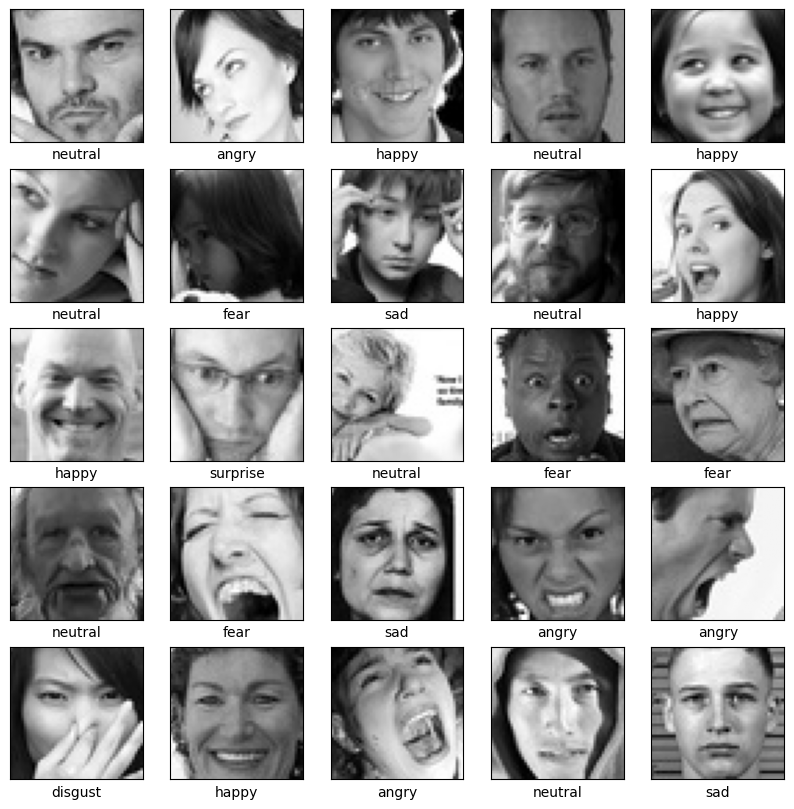

In [31]:
fig = plt.figure(figsize=(10, 10))
idx = np.random.choice(len(x_train), 25, replace=False)
for i, j in enumerate(idx):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[j], cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(class_names[y_train[j]])
plt.show()

Preprocess

In [32]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print(x_train.shape, x_val.shape, x_test.shape)

(18373, 48, 48) (4594, 48, 48) (7178, 48, 48)


Scalling

In [33]:
x_train_scaled = x_train / 255
x_val_scaled = x_val / 255
x_test_scaled = x_test / 255

print(x_train_scaled.min(),"-", x_train_scaled.max())

0.0 - 1.0


Model

In [34]:
set_random_seed(9999)

model = Sequential([
    Flatten(input_shape=(48, 48)),
    Dense(100, activation='relu'),
    Dense(100, activation='relu'),
    Dense(100, activation='relu'),
    Dense(7, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │       230,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           707 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 251,407 (982.06 KB)

 Trainable params: 251,407 (982.06 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
c_weights = compute_class_weight(class_weight="balanced",
                                 classes=np.unique(y_train),
                                 y=y_train)
class_weight_dict = dict(zip(np.unique(y_train), c_weights))
class_weight_dict

{np.int64(0): np.float64(1.0264819263646014),
 np.int64(1): np.float64(9.40757808499744),
 np.int64(2): np.float64(1.0010351966873705),
 np.int64(3): np.float64(0.5684891240446796),
 np.int64(4): np.float64(0.8261612482575655),
 np.int64(5): np.float64(0.8491472939871516),
 np.int64(6): np.float64(1.2929627023223083)}

In [39]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['acc'])

history = model.fit(x_train_scaled, y_train,
                    validation_data=(x_val_scaled, y_val),
                    epochs=100,
                    class_weight=class_weight_dict)

Epoch 1/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.2193 - loss: 1.8433 - val_acc: 0.1946 - val_loss: 1.8579
Epoch 2/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.2197 - loss: 1.8412 - val_acc: 0.1918 - val_loss: 1.8632
Epoch 3/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.2190 - loss: 1.8372 - val_acc: 0.2055 - val_loss: 1.8480
Epoch 4/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.2156 - loss: 1.8422 - val_acc: 0.1963 - val_loss: 1.8542
Epoch 5/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - acc: 0.2274 - loss: 1.8339 - val_acc: 0.2236 - val_loss: 1.8375
Epoch 6/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.2218 - loss: 1.8326 - val_acc: 0.2619 - val_loss: 1.8067
Epoch 7/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.2330 - loss: 1.8264 - val_acc: 0.2427 - val_loss: 1.8251
Epoch 8/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.2290 - loss: 1.8323 - val_acc: 0.2440 - val_loss: 1.8244
Epoch 9/100
575/575 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/

In [40]:
history_df = pd.DataFrame(history.history)
history_df.head()

,acc,loss,val_acc,val_loss
0,0.219289,1.843263,0.194602,1.857919
1,0.219725,1.841164,0.191772,1.863245
2,0.218963,1.837189,0.205485,1.847955
3,0.215588,1.842158,0.196343,1.854196
4,0.227399,1.833929,0.223552,1.837491


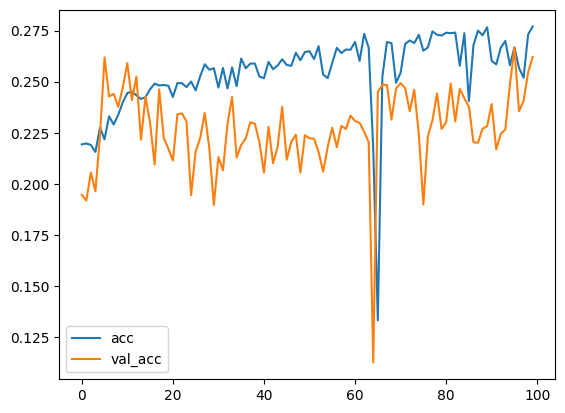

In [42]:
history_df[['acc', 'val_acc']].plot();

using the test dataset

In [43]:
y_pred_test = model.predict(x_test_scaled).argmax(axis=1)
y_pred_test

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([3, 3, 6, ..., 1, 6, 1])

In [45]:
print(accuracy_score(y_test, y_pred_test))
model.evaluate(x_test_scaled, y_test)

0.2665087768180552
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.2665 - loss: 1.8335


[1.8334614038467407, 0.2665087878704071]

In [46]:
print(classification_report(y_test, y_pred_test, target_names=class_names))

              precision    recall  f1-score   support

       angry       0.20      0.02      0.03       958
     disgust       0.04      0.63      0.07       111
        fear       0.17      0.03      0.05      1024
       happy       0.42      0.51      0.46      1774
     neutral       0.27      0.33      0.30      1233
         sad       0.25      0.02      0.04      1247
    surprise       0.35      0.54      0.42       831

    accuracy                           0.27      7178
   macro avg       0.24      0.30      0.20      7178
weighted avg       0.29      0.27      0.23      7178



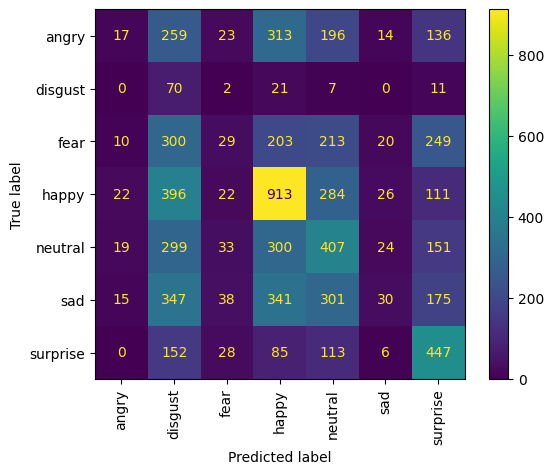

In [48]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test,
                                        display_labels=class_names,
                                        xticks_rotation='vertical');

Deployment

In [50]:
model.save("emotion_model.keras")
files.download("emotion_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>